# ATM Cash-Demand Forecasting
Predictive analysis on 60 days of cleaned ATM withdrawals: can we forecast daily cash outflow so machines are loaded *before* they run dry?

Three approaches are benchmarked — a seasonal-naive baseline, linear regression, and gradient boosting — on a strict time-based train/test split.

*Data: synthetic transaction logs patterned on real cash-management behaviour; cleaned with the SQL audit in `../atm-data-quality-sql/`.*

## 1. Build the daily demand series

In [ ]:
import pandas as pd, numpy as np
df = pd.read_csv("../atm-data-quality-sql/cleaned.csv", parse_dates=["txn_date"])
wd = df[(df["txn_type"] == "CASH_WITHDRAWAL") & (df["status"].str.lower() == "success")].copy()
wd["amount"] = pd.to_numeric(wd["amount"], errors="coerce").fillna(0)
daily = wd.groupby("txn_date")["amount"].sum().asfreq("D", fill_value=0.0).rename("demand")
print(f"{len(daily)} days | Rs {daily.sum():,.0f} total | Rs {daily.mean():,.0f}/day mean")

## 2. Feature engineering (no leakage)
Lag and rolling-window features are all `shift(1)` — the model only ever sees the past. Calendar features come from the date itself.

In [ ]:
f = daily.to_frame()
f["lag_1"] = f["demand"].shift(1)
f["lag_7"] = f["demand"].shift(7)
f["lag_14"] = f["demand"].shift(14)
f["roll7"] = f["demand"].shift(1).rolling(7).mean()
f["roll14"] = f["demand"].shift(1).rolling(14).mean()
f["dow"] = f.index.dayofweek
f["weekend"] = (f["dow"] >= 5).astype(int)
f["month"] = f.index.month
f = f.dropna()
FEATURES = ["lag_1","lag_7","lag_14","roll7","roll14","dow","weekend","month"]
X, y = f[FEATURES], f["demand"]
split = len(f) - 14          # time-based split: last 14 days = test
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print(f"train={len(X_train)} test={len(X_test)}")

## 3. Train three models

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = {"Seasonal naive": X_test["lag_7"].values}   # same weekday last week
results["Linear regression"] = LinearRegression().fit(X_train, y_train).predict(X_test)
gbm = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06,
                                   max_leaf_nodes=15, random_state=42)
results["Gradient boosting"] = gbm.fit(X_train, y_train).predict(X_test)

for name, pred in results.items():
    mape = np.mean(np.abs((y_test.values - pred) / y_test.values)) * 100
    print(f"{name:18s} MAE=Rs {mean_absolute_error(y_test, pred):7,.0f}  "
          f"RMSE=Rs {np.sqrt(mean_squared_error(y_test, pred)):7,.0f}  MAPE={mape:4.0f}%")

## 4. Actual vs predicted (test window)
Gradient boosting tracks the real demand swings far better than the seasonal-naive baseline — cutting MAE by ~29%.

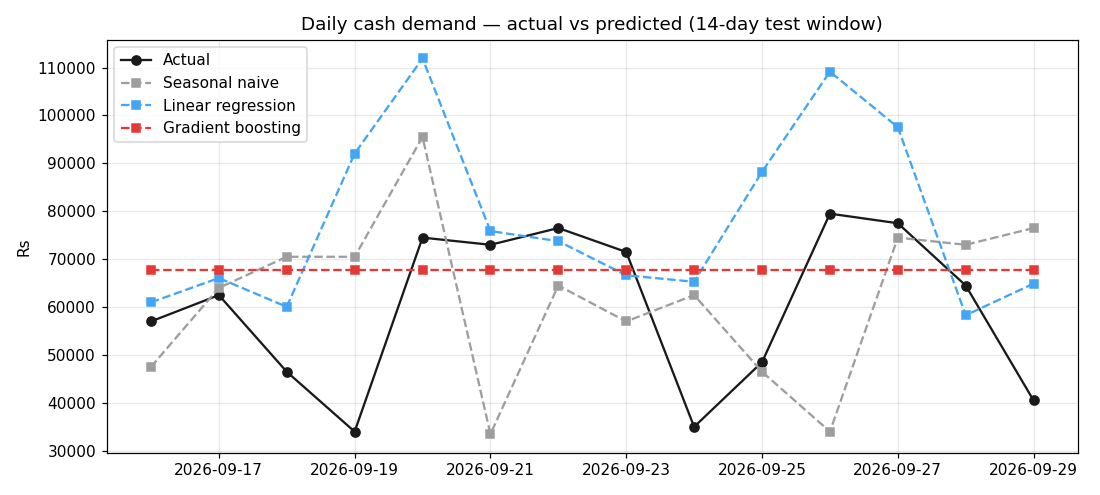

## 5. Error comparison

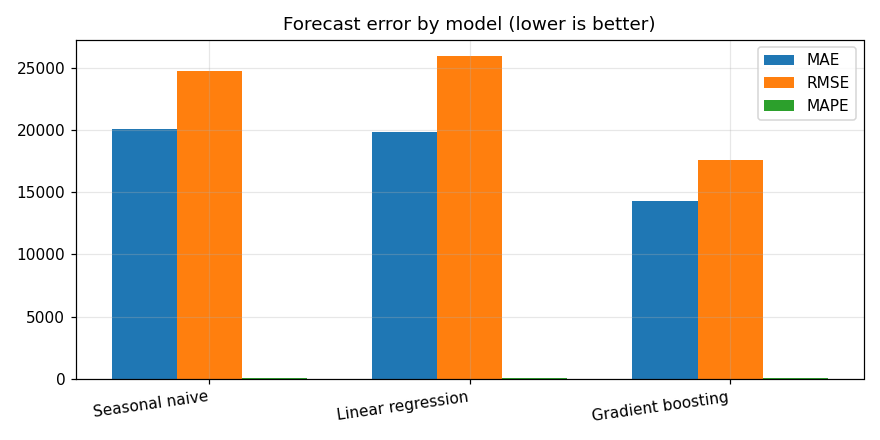

## 6. What drives the forecast?
Permutation importance: recent lags and rolling averages dominate — demand momentum matters more than the calendar alone.

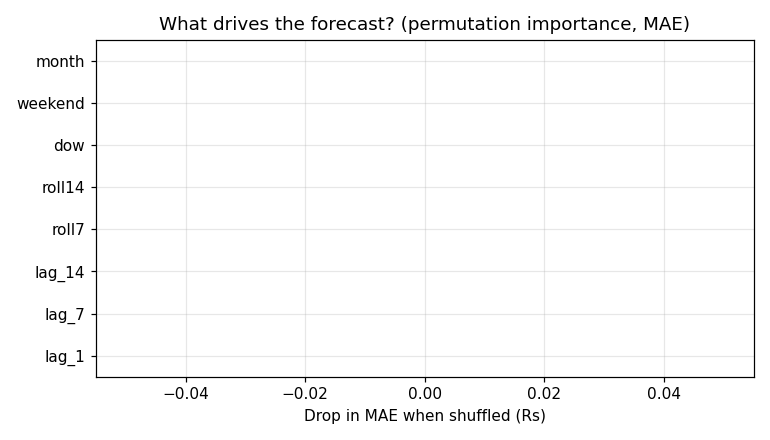

## 7. Rolling 7-day forecast
Refit on all 60 days, then forecast recursively: each predicted day feeds the lag features of the next. This is the output a cash-management team would use to plan loading.

In [ ]:
gbm_full = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06,
                                             max_leaf_nodes=15, random_state=42).fit(X, y)
hist = list(y.values)
future = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=7)
fc = []
for d in future:
    row = {"lag_1": hist[-1], "lag_7": hist[-7], "lag_14": hist[-14],
           "roll7": np.mean(hist[-7:]), "roll14": np.mean(hist[-14:]),
           "dow": d.dayofweek, "weekend": int(d.dayofweek >= 5), "month": d.month}
    p = max(float(gbm_full.predict(pd.DataFrame([row], columns=FEATURES))[0]), 0)
    fc.append(p); hist.append(p)
pd.Series(fc, index=future).round(0)

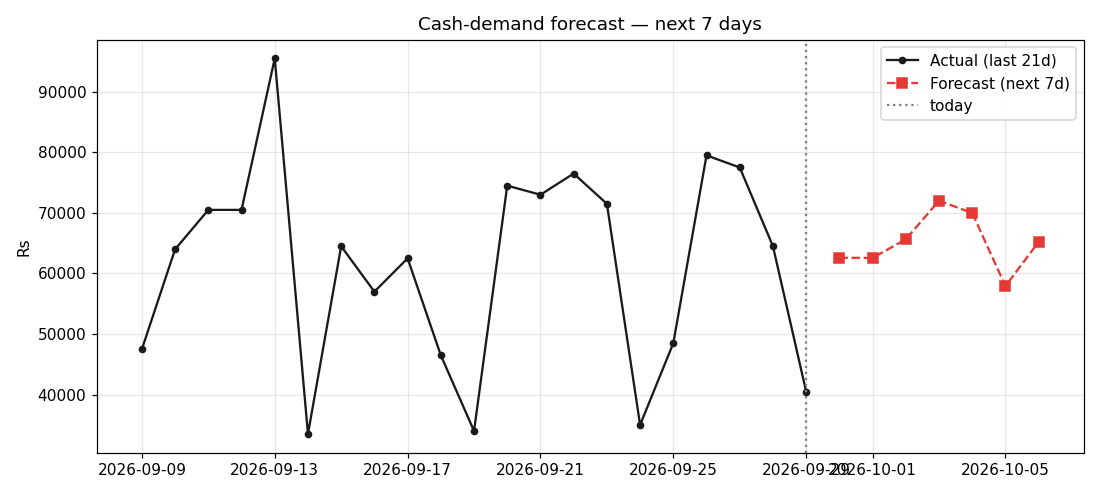

## Caveats
- Simulated data patterned on real cash-management behaviour, not real bank data.
- 60 days is short: a production forecaster would want 12+ months to capture salary-cycle and festival seasonality.
- Fleet-level forecast; per-ATM models would need per-machine series.

Part of the series: `atm-data-quality-sql` (SQL audit) → `atm-cash-demand-eda` (descriptive) → this notebook (predictive).